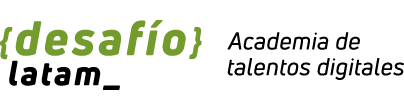

# <font color = 'green'>Implementación de Redes Convolucionales</font>


El Instituto Canadiense de Investigación Avanzada (CIFAR por sus siglas en inglés) desarrolló un conjunto de datos estándar de visión artificial y Deep Learning para este problema. El conjunto de datos CIFAR-10 (10 clases) consta de 60.000 fotos divididas en 10 clases. Las clases incluyen objetos comunes como aviones, automóviles, pájaros, gatos, etc. El conjunto se divide en 50.000 imágenes para train y 10.000 para test. Las fotos son en color con canales rojo, verde y azul, por lo que tienen un tamaño 32x32x3 píxeles.

### <font color = 'green'>Carga de librerías y datos</font>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import cifar10
from keras.models import Sequential, load_model, save_model
from keras.callbacks import EarlyStopping
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input, BatchNormalization
from keras.constraints import MaxNorm
from keras.optimizers import SGD
from keras.regularizers import L2
from keras.preprocessing.image import ImageDataGenerator

from sklearn.preprocessing import OneHotEncoder
import os

In [2]:
cifar10_labels = {0: 'airplane', 1: 'automobile', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog',
                  6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}

def show_images(images, target, pred=[], nrow=3, ncol=3):
    fig, ax = plt.subplots(nrows=nrow, ncols=ncol, figsize=(4 + ncol, 4 + nrow/2.5),
                          sharex=True, sharey=True)

    for i in range(nrow):
        for j in range(ncol):
            alea = np.random.randint(0, images.shape[0]+1)
            ax[i, j].imshow(images[alea])
            tit = '['+cifar10_labels[target[alea]] + ']'
            if len(pred) > 0:
             tit += ' ' + cifar10_labels[pred[alea]]
            ax[i, j].set_title(tit, fontsize=10)
            ax[i, j].set_axis_off()
    plt.tight_layout()
    plt.show();

In [3]:
# carga de datos
'''
| Label | Description |
|:-----:|-------------|
|   0   | airplane    |
|   1   | automobile  |
|   2   | bird        |
|   3   | cat         |
|   4   | deer        |
|   5   | dog         |
|   6   | frog        |
|   7   | horse       |
|   8   | ship        |
|   9   | truck       |
'''
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

170498071/170498071 [==============================] - 5s 0us/step


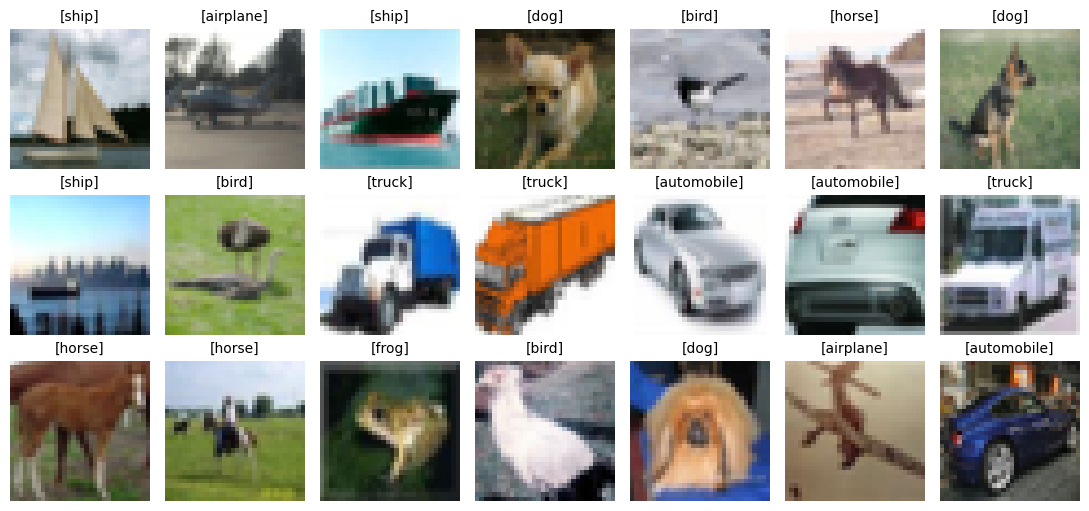

In [4]:
show_images(X_train, y_train.ravel(), nrow=3, ncol=7)

### <font color = 'green'>Normalización</font>

In [5]:
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

### <font color = 'green'>One-hot encoding</font>

In [6]:
y_train = OneHotEncoder().fit_transform(y_train).toarray()
y_test = OneHotEncoder().fit_transform(y_test).toarray()
n_class = y_test.shape[1]

## <font color = 'green'>CNN - Arquitectura 1</font>

In [7]:
ann_cnn1 = Sequential()
ann_cnn1.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))

ann_cnn1.add(Conv2D(32, (3, 3), activation='relu', kernel_constraint=MaxNorm(3), padding='same'))
ann_cnn1.add(Dropout(.3))
ann_cnn1.add(Conv2D(32, (3, 3), activation='relu', kernel_constraint=MaxNorm(3), padding='same'))
ann_cnn1.add(MaxPooling2D(pool_size=(2, 2)))
ann_cnn1.add(Flatten())

ann_cnn1.add(Dense(512, activation='relu', kernel_constraint=MaxNorm(3)))
ann_cnn1.add(Dropout(.2))

ann_cnn1.add(Dense(n_class, activation='softmax', kernel_constraint=MaxNorm(3)))

ann_cnn1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
ann_cnn1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 32, 32, 32)        896       
                                                                 
 dropout (Dropout)           (None, 32, 32, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        9248      
                                                                 
 max_pooling2d (MaxPooling2  (None, 16, 16, 32)        0         
 D)                                                              
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 512)               4194816   
                                                        

### <font color = 'green'>Entrenamiento y evaluación del modelo</font>

In [8]:
epochs = 10
ann_cnn1_hist = ann_cnn1.fit(X_train, y_train, batch_size=100, epochs=epochs, validation_data=(X_test, y_test))
score = ann_cnn1.evaluate(X_test, y_test, verbose=0)
print(f'\n\n accuracy: {score[1]*100}%')

Epoch 1/10
500/500 [==============================] - 192s 382ms/step - loss: 1.5984 - accuracy: 0.4251 - val_loss: 1.2467 - val_accuracy: 0.5590
Epoch 2/10
500/500 [==============================] - 193s 385ms/step - loss: 1.1385 - accuracy: 0.5977 - val_loss: 1.0511 - val_accuracy: 0.6316
Epoch 3/10
500/500 [==============================] - 197s 393ms/step - loss: 0.9670 - accuracy: 0.6577 - val_loss: 0.9719 - val_accuracy: 0.6616
Epoch 4/10
500/500 [==============================] - 195s 391ms/step - loss: 0.8667 - accuracy: 0.6928 - val_loss: 0.9216 - val_accuracy: 0.6771
Epoch 5/10
500/500 [==============================] - 197s 394ms/step - loss: 0.7950 - accuracy: 0.7206 - val_loss: 0.9163 - val_accuracy: 0.6751
Epoch 6/10
500/500 [==============================] - 194s 388ms/step - loss: 0.7329 - accuracy: 0.7411 - val_loss: 0.9056 - val_accuracy: 0.6859
Epoch 7/10
500/500 [==============================] - 193s 387ms/step - loss: 0.6820 - accuracy: 0.7590 - val_loss: 0.9241 -

## <font color = 'green'>CNN - Arquitectura 2</font>

In [ ]:
ann_cnn2 = Sequential()
ann_cnn2.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))

ann_cnn2.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(Conv2D(32, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(MaxPooling2D((2, 2)))
ann_cnn2.add(BatchNormalization())
ann_cnn2.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(MaxPooling2D((2, 2)))
ann_cnn2.add(BatchNormalization())
ann_cnn2.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(BatchNormalization())
ann_cnn2.add(Dropout(.2))
ann_cnn2.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
ann_cnn2.add(MaxPooling2D((2, 2)))
ann_cnn2.add(BatchNormalization())
ann_cnn2.add(Flatten())
ann_cnn2.add(Dense(1024, activation='relu', use_bias=True, kernel_constraint=MaxNorm(3)))
ann_cnn2.add(Dropout(.2))
ann_cnn2.add(Dense(units=n_class, activation='softmax', use_bias=True, kernel_constraint=MaxNorm(3)))

ann_cnn2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
ann_cnn2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 32, 32, 32)        896       
                                                                 
 conv2d_3 (Conv2D)           (None, 32, 32, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 32)       0         
 2D)                                                             
                                                                 
 batch_normalization (BatchN  (None, 16, 16, 32)       128       
 ormalization)                                                   
                                                                 
 conv2d_4 (Conv2D)           (None, 16, 16, 64)        18496     
                                                                 
 conv2d_5 (Conv2D)           (None, 16, 16, 64)       

In [ ]:
epochs = 24

ann_cnn2_hist = ann_cnn2.fit(X_train, y_train, batch_size=128, epochs=epochs, validation_data=(X_test, y_test), shuffle=True)
score = ann_cnn2.evaluate(X_test, y_test, verbose=0)
print(f'accuracy: {score[1]*100}%')

Epoch 1/24
391/391 [==============================] - 32s 77ms/step - loss: 6.4111 - accuracy: 0.1994 - val_loss: 3.8314 - val_accuracy: 0.2087
Epoch 2/24
391/391 [==============================] - 28s 73ms/step - loss: 4.5935 - accuracy: 0.2093 - val_loss: 4.1292 - val_accuracy: 0.1909
Epoch 3/24
391/391 [==============================] - 29s 73ms/step - loss: 3.6892 - accuracy: 0.2401 - val_loss: 2.6232 - val_accuracy: 0.2246
Epoch 4/24
391/391 [==============================] - 29s 73ms/step - loss: 4.0126 - accuracy: 0.2558 - val_loss: 4.8346 - val_accuracy: 0.1844
Epoch 5/24
391/391 [==============================] - 29s 73ms/step - loss: 4.4222 - accuracy: 0.2350 - val_loss: 4.2242 - val_accuracy: 0.1771
Epoch 6/24
391/391 [==============================] - 29s 73ms/step - loss: 3.5305 - accuracy: 0.2918 - val_loss: 2.4574 - val_accuracy: 0.3642
Epoch 7/24
391/391 [==============================] - 29s 73ms/step - loss: 3.2601 - accuracy: 0.3224 - val_loss: 4.6644 - val_accuracy:

In [ ]:
save_model(ann_cnn2,'cnn_ark2.keras')

## <font color = 'green'>CNN - Arquitectura 3 (VGG-19)</font>

In [ ]:
# Recordar que en VGG-19 las imágenes de entrada son de 224x224x3
ll2 = 0.0005 # lambda l2

ann_cnn3 = Sequential()
ann_cnn3.add(Input(shape=(X_train.shape[1], X_train.shape[2], X_train.shape[3])))

# Dos capas convolucionales de 64 filtros para kernels de 3x3 s=1, p=1
ann_cnn3.add(Conv2D(64, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(64, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(MaxPooling2D((2, 2), strides=1))
ann_cnn3.add(BatchNormalization())
ann_cnn3.add(Dropout(.3))

# Dos capas  convolucionales de 128 filtros para kernel de 3x3 s=1, p=1
ann_cnn3.add(Conv2D(128, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(128, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(MaxPooling2D((2, 2), strides=1))
ann_cnn3.add(BatchNormalization())
ann_cnn3.add(Dropout(.3))

# Tres capas convolucionales de 256 filtros para kernel de 3x3 s=1, p=1
ann_cnn3.add(Conv2D(256, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(256, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(256, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(256, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(MaxPooling2D((2, 2), strides=1))
ann_cnn3.add(BatchNormalization())
ann_cnn3.add(Dropout(.3))

# Tres capas convolucionales de 512 filtros para kernel de 3x3 s=1, p=1
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(MaxPooling2D((2, 2), strides=1))
ann_cnn3.add(BatchNormalization())
ann_cnn3.add(Dropout(.3))

# Tres capas convolucionales de 512 filtros para kernel de 3x3 s=1, p=1
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(Conv2D(512, (3, 3), activation='relu', padding='same', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3), kernel_regularizer=L2(ll2)))
ann_cnn3.add(MaxPooling2D((2, 2), strides=1))
ann_cnn3.add(Dropout(.3))

# la original tiene 4096 capa FC
ann_cnn3.add(Flatten())
ann_cnn3.add(Dense(512, activation='relu', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3)))
ann_cnn3.add(BatchNormalization())
ann_cnn3.add(Dropout(.2))
ann_cnn3.add(Dense(512, activation='relu', kernel_initializer='glorot_normal', kernel_constraint=MaxNorm(3)))
ann_cnn3.add(Dropout(.2))

ann_cnn3.add(Dense(n_class, activation='softmax'))
ann_cnn3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

ann_cnn3.summary()



Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_11 (Conv2D)          (None, 32, 32, 64)        1792      
                                                                 
 conv2d_12 (Conv2D)          (None, 32, 32, 64)        36928     
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 31, 31, 64)       0         
 2D)                                                             
                                                                 
 batch_normalization_4 (Batc  (None, 31, 31, 64)       256       
 hNormalization)                                                 
                                                                 
 dropout_4 (Dropout)         (None, 31, 31, 64)        0         
                                                                 
 conv2d_13 (Conv2D)          (None, 31, 31, 128)      

In [ ]:
# No ejecutar tiempo excesivo en procesamiento
epochs = 1
ann_cnn3_hist = ann_cnn3.fit(X_train, y_train, batch_size=512, epochs=epochs, validation_data=(X_test, y_test))
score = ann_cnn3.evaluate(X_test, y_test, verbose=0)
print(f'accuracy: {score[1]*100}%')

 1/98 [..............................] - ETA: 1:37:52 - loss: 6.0137 - accuracy: 0.0859

## <font color = 'green'>Aplicando el modelo ann_cnn2</font>

In [ ]:
# Se carga el modelo entreando y realizamos predicciones
ann_cnn2_pre = load_model('cnn_ark2.keras')

yhat_test = ann_cnn2_pre.predict(X_test)
y_test_class = np.apply_along_axis(np.argmax, axis=1, arr=y_test)
yhat_class_test = np.apply_along_axis(np.argmax, axis=1, arr=yhat_test)

313/313 [==============================] - 3s 8ms/step


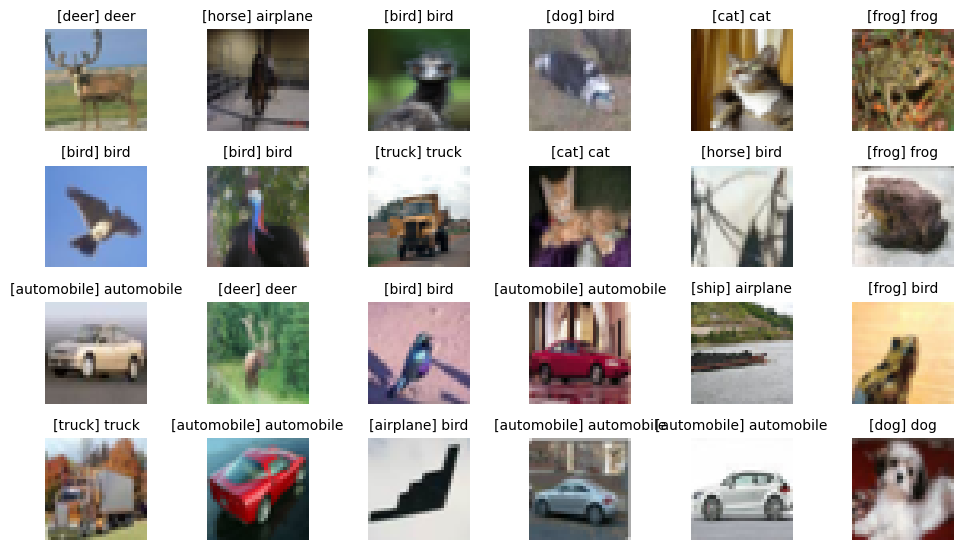

In [ ]:
show_images(X_test, y_test_class, pred=yhat_class_test, nrow=4, ncol=6)